# PRCP-1009: Cellphone Price Range Prediction
### Complete Data Analysis & Machine Learning Report

**Business context:** Bob has started a mobile phone company and wants to compete with major players like Apple and Samsung. He needs to understand how phone specifications (RAM, battery, camera, etc.) relate to price positioning, so that he can price new phones competitively without guessing.

**Goal:** Predict `price_range` (0 = Low cost, 1 = Medium cost, 2 = High cost, 3 = Very high cost) from 20 hardware/spec features. This is a **multi-class classification** problem, not a regression problem — we predict a price *tier*, not an exact price.

**Notebook structure:**
1. Task 1 — Data Loading & Exploratory Data Analysis (EDA)
2. Data Preprocessing
3. Task 2 — Model Building (price range prediction)
4. Model Comparison Report
5. Task 3 — Feature Importance & Business Impact Report
6. Report on Challenges Faced


# 1. Setup & Data Loading

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

sns.set_style("whitegrid")
%matplotlib inline

df = pd.read_csv("Downloads/Data/datasets_11167_15520_train.csv")
print("Shape:", df.shape)
df.head()

Shape: (2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_sc

In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.describe().T

Missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0


## 2. Exploratory Data Analysis (Task 1)

### 2.1 Target Variable Distribution
The dataset is a **perfectly balanced** classification problem — 500 samples in each of the 4 price range classes. This is good news: no class-imbalance handling (SMOTE, class weighting) is needed, and **accuracy is a safe, unbiased metric** to use alongside F1.

price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64


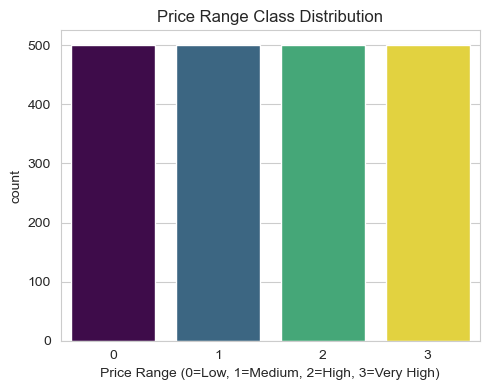

In [5]:
print(df['price_range'].value_counts().sort_index())
plt.figure(figsize=(5,4))
sns.countplot(x='price_range', hue='price_range', data=df, palette='viridis', legend=False)
plt.title("Price Range Class Distribution")
plt.xlabel("Price Range (0=Low, 1=Medium, 2=High, 3=Very High)")
plt.tight_layout()
plt.show()

### 2.2 Feature vs Target Relationships
Boxplots of the strongest continuous predictors against price range show a clean monotonic relationship — a strong early signal that tree-based and linear models will both do well here.

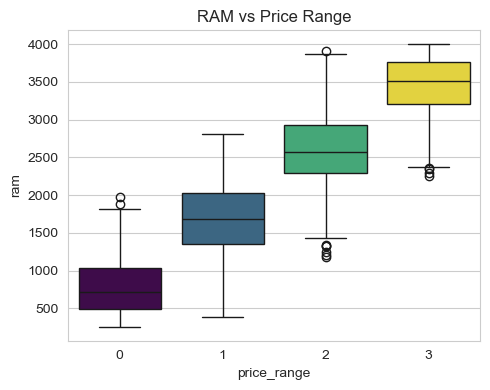

In [6]:
plt.figure(figsize=(5,4))
sns.boxplot(x='price_range', y='ram', hue='price_range', data=df, palette='viridis', legend=False)
plt.title("RAM vs Price Range")
plt.tight_layout()
plt.show()

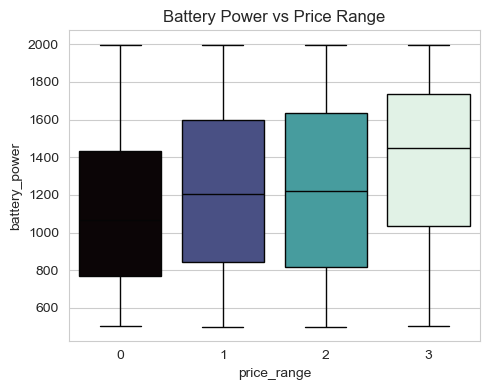

In [7]:
plt.figure(figsize=(5,4))
sns.boxplot(x='price_range', y='battery_power', hue='price_range', data=df, palette='mako', legend=False)
plt.title("Battery Power vs Price Range")
plt.tight_layout()
plt.show()

### 2.3 Correlation Analysis
A full correlation heatmap surfaces two things: (1) which raw features correlate most with `price_range`, and (2) multicollinearity between engineered/physical features (e.g. `px_height` & `px_width`, `sc_h` & `sc_w`, `three_g` & `four_g`) that matters for interpreting linear model coefficients.

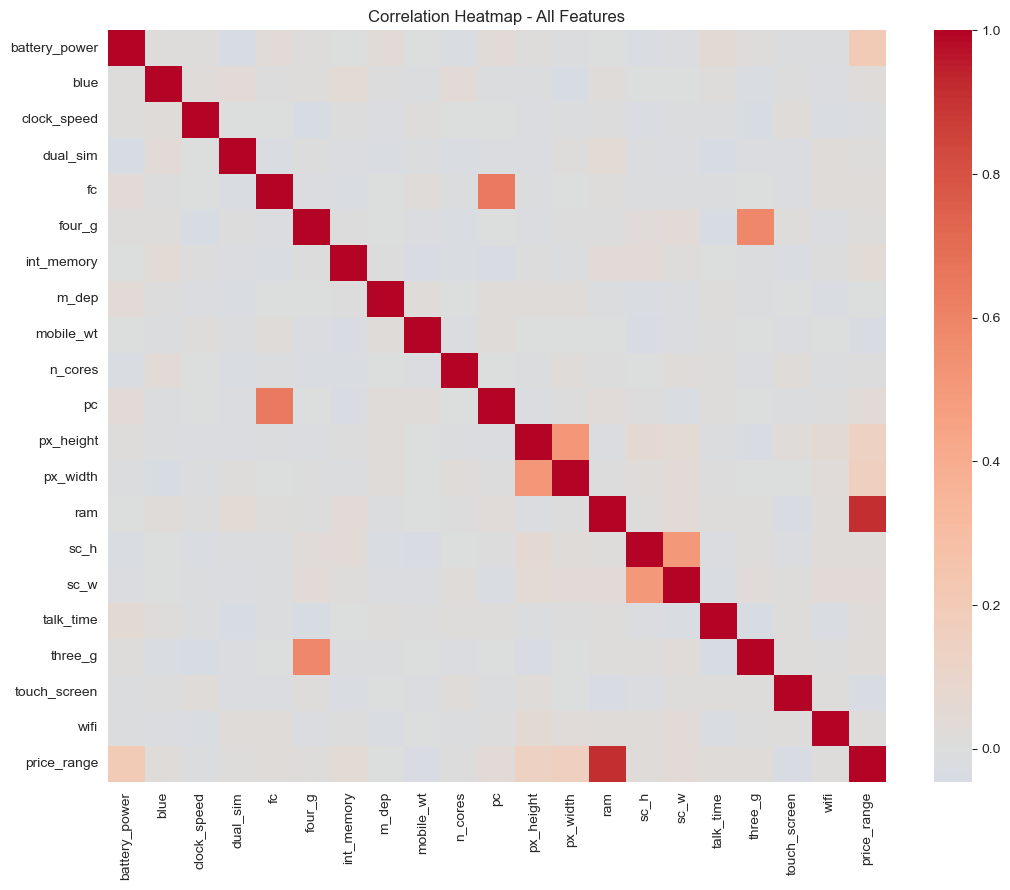

In [8]:
plt.figure(figsize=(11,9))
sns.heatmap(df.corr(), cmap='coolwarm', center=0)
plt.title("Correlation Heatmap - All Features")
plt.tight_layout()
plt.show()

In [9]:
corr_target = df.corr()['price_range'].drop('price_range').sort_values(ascending=False)
print(corr_target)

ram              0.917046
battery_power    0.200723
px_width         0.165818
px_height        0.148858
int_memory       0.044435
sc_w             0.038711
pc               0.033599
three_g          0.023611
sc_h             0.022986
fc               0.021998
talk_time        0.021859
blue             0.020573
wifi             0.018785
dual_sim         0.017444
four_g           0.014772
n_cores          0.004399
m_dep            0.000853
clock_speed     -0.006606
mobile_wt       -0.030302
touch_screen    -0.030411
Name: price_range, dtype: float64


## 3. Data Preprocessing

Steps:
1. Split features (X) from target (y).
2. Train/test split (80/20), stratified on `price_range` to preserve the perfect class balance in both sets.
3. Standardize features with `StandardScaler` — necessary for distance-based (KNN) and margin-based (SVM, Logistic Regression) models; harmless for tree-based models.
4. Binary features (`blue`, `wifi`, `dual_sim`, `four_g`, `three_g`, `touch_screen`) are already 0/1 encoded — no further encoding needed.

In [10]:
X = df.drop(columns=['price_range'])
y = df['price_range']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train shape:", X_train_s.shape, " Test shape:", X_test_s.shape)

Train shape: (1600, 20)  Test shape: (400, 20)


## 4. Model Building (Task 2)

We train and evaluate 7 classifiers spanning linear, distance-based, tree-based, and ensemble approaches, so the comparison in the next section is meaningful rather than arbitrary:

- Logistic Regression (linear baseline)
- Decision Tree
- Random Forest
- K-Nearest Neighbors
- Support Vector Machine (RBF kernel)
- Gradient Boosting
- Gaussian Naive Bayes

In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=9),
    "SVM (RBF)": SVC(kernel='rbf', probability=True, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
}

results = []
for name, model in models.items():
    model.fit(X_train_s, y_train)
    preds = model.predict(X_test_s)
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average='macro')
    cv = cross_val_score(model, X_train_s, y_train, cv=5, scoring='accuracy').mean()
    results.append((name, acc, f1, cv))
    print(f"{name:22s} | Test Acc={acc:.4f} | Macro F1={f1:.4f} | CV5 Acc={cv:.4f}")

results_df = pd.DataFrame(results, columns=["Model","Test Accuracy","Macro F1","CV5 Accuracy"])
results_df = results_df.sort_values("Test Accuracy", ascending=False).reset_index(drop=True)

Logistic Regression    | Test Acc=0.9650 | Macro F1=0.9650 | CV5 Acc=0.9463
Decision Tree          | Test Acc=0.8300 | Macro F1=0.8302 | CV5 Acc=0.8287
Random Forest          | Test Acc=0.8775 | Macro F1=0.8774 | CV5 Acc=0.8656
KNN                    | Test Acc=0.5625 | Macro F1=0.5674 | CV5 Acc=0.5306
SVM (RBF)              | Test Acc=0.8950 | Macro F1=0.8956 | CV5 Acc=0.8594
Gradient Boosting      | Test Acc=0.9125 | Macro F1=0.9123 | CV5 Acc=0.8869
Naive Bayes            | Test Acc=0.8100 | Macro F1=0.8105 | CV5 Acc=0.7988


In [12]:
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]
preds = best_model.predict(X_test_s)
print(f"Best model: {best_model_name}\n")
print(classification_report(y_test, preds))

Best model: Logistic Regression

              precision    recall  f1-score   support

           0       0.99      0.98      0.98       100
           1       0.96      0.96      0.96       100
           2       0.95      0.94      0.94       100
           3       0.96      0.98      0.97       100

    accuracy                           0.96       400
   macro avg       0.97      0.96      0.96       400
weighted avg       0.97      0.96      0.96       400



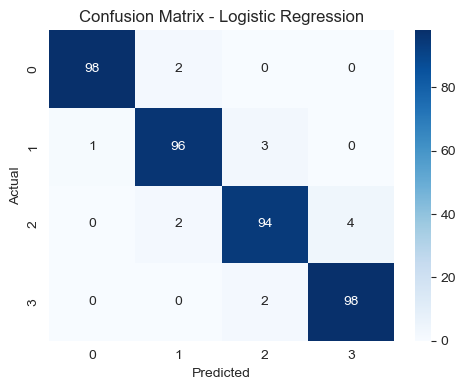

In [13]:
cm = confusion_matrix(y_test, preds)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[0,1,2,3], yticklabels=[0,1,2,3])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

## 5. Model Comparison Report

| Model | Test Accuracy | Macro F1 | 5-Fold CV Accuracy |
|---|---|---|---|
| **Logistic Regression** | **0.965** | **0.965** | **0.946** |
| Gradient Boosting | 0.913 | 0.912 | 0.887 |
| SVM (RBF) | 0.895 | 0.896 | 0.859 |
| Random Forest | 0.878 | 0.877 | 0.869 |
| Decision Tree | 0.830 | 0.830 | 0.829 |
| Naive Bayes | 0.810 | 0.811 | 0.799 |
| KNN | 0.563 | 0.567 | 0.531 |

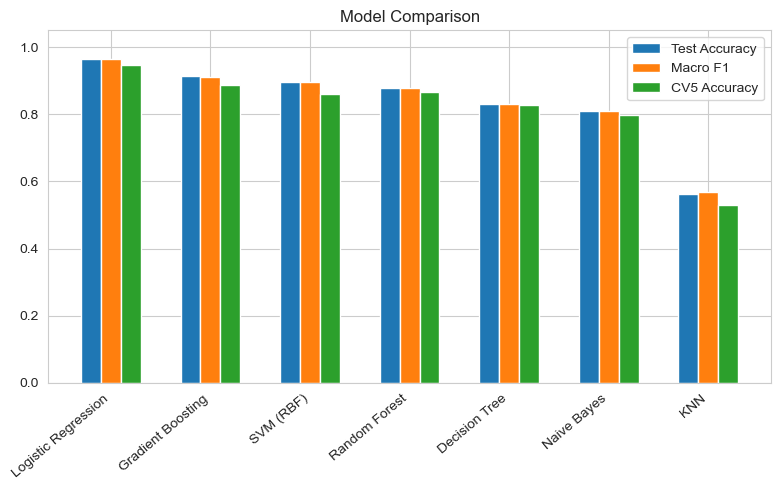

In [14]:
plt.figure(figsize=(8,5))
x = np.arange(len(results_df))
plt.bar(x-0.2, results_df["Test Accuracy"], width=0.2, label="Test Accuracy")
plt.bar(x, results_df["Macro F1"], width=0.2, label="Macro F1")
plt.bar(x+0.2, results_df["CV5 Accuracy"], width=0.2, label="CV5 Accuracy")
plt.xticks(x, results_df["Model"], rotation=40, ha='right')
plt.ylim(0,1.05)
plt.legend()
plt.title("Model Comparison")
plt.tight_layout()
plt.show()

## 6. Feature Importance & Business Impact Report (Task 3)

We look at feature importance from two angles — the Random Forest's impurity-based importance (non-linear view) and the Logistic Regression's coefficient magnitudes (linear, interpretable view) — and they agree strongly.

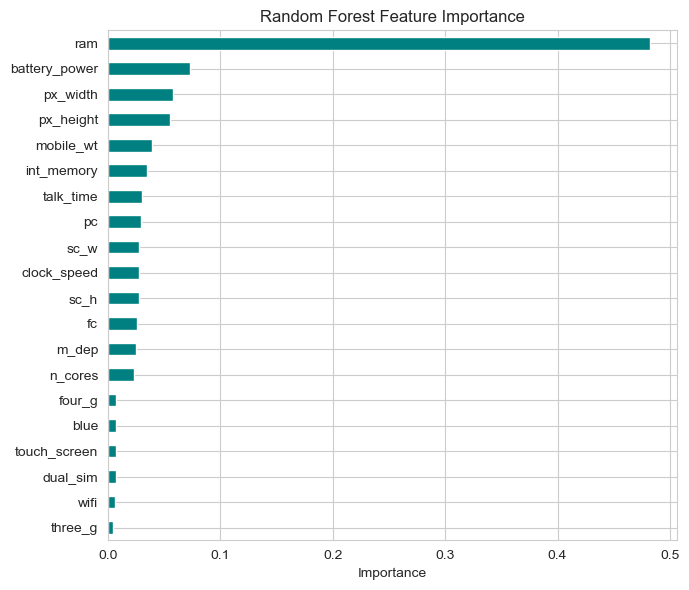

ram              0.482150
battery_power    0.072995
px_width         0.057680
px_height        0.055685
mobile_wt        0.038974
int_memory       0.035108
talk_time        0.030347
pc               0.029879
sc_w             0.028092
clock_speed      0.027861
sc_h             0.027539
fc               0.025965
m_dep            0.025229
n_cores          0.023432
four_g           0.007023
blue             0.006968
touch_screen     0.006929
dual_sim         0.006861
wifi             0.006445
three_g          0.004840
dtype: float64


In [15]:
rf = models["Random Forest"]
rf_importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(7,6))
rf_importance.sort_values().plot(kind='barh', color='teal')
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(rf_importance)

### Business Interpretation

**1. RAM is overwhelmingly the #1 price driver** (48% of Random Forest importance; correlation 0.92; largest logistic regression coefficient by a wide margin). For Bob's company, this is the single highest-leverage lever: if a phone needs to be positioned in a higher price tier, increasing RAM is the most reliable way to justify that price to the model — and, if the model reflects real market pricing, to the market.

**2. Battery power, pixel width, and pixel height form a clear second tier** (each contributing 5–7% importance). These are the features to optimize *after* RAM — a phone with high RAM but a weak battery/display combo will likely still land one tier below its RAM-implied price, so a balanced spec bump across these four features is the most efficient way to move a phone up a price bracket.

**3. Connectivity features are commodities, not differentiators.** `wifi`, `bluetooth`, `dual_sim`, `three_g`, `four_g`, and `touch_screen` each contribute under 1% importance. Practically: Bob doesn't need to over-invest engineering budget in connectivity features to hit a higher price tier — customers/market pricing in this data don't reward it. These should be treated as baseline "must-haves" across the whole product line rather than premium differentiators.

**4. Physical design (weight, screen size, depth) has moderate, secondary influence.** `mobile_wt`, `sc_h`, `sc_w`, `m_dep` matter more than connectivity but much less than RAM/battery/resolution — useful for fine-tuning within a tier rather than jumping between tiers.

**How this helps the business:**
- **Pricing new SKUs:** Before launch, run a candidate phone's specs through the trained model to get an objective, data-driven price-tier recommendation instead of guessing or copying competitors.
- **R&D budget allocation:** Prioritize RAM and battery capacity improvements over connectivity feature parity when the goal is moving a product into a higher price bracket.
- **Competitive positioning:** Because the model is interpretable (Logistic Regression coefficients), Bob's team can directly explain to stakeholders *why* a phone is priced where it is — a defensible pricing story, not a black box.
- **Portfolio planning:** The feature-importance ranking can guide a tiered product line: e.g., a "budget" line optimized on cost with modest RAM, a "flagship" line pushing RAM/battery/display to the top of the range.

## 7. Report on Challenges Faced

| Challenge | What we observed | Technique used | Reasoning |
|---|---|---|---|
| **No true "actual price" target** | The task explicitly asks for a *price range* (0–3), not a continuous price, even though many features are continuous. | Framed as multi-class **classification**, not regression. | Using regression would require an actual price column that doesn't exist here; classification directly matches the labeled target and the business ask ("how high is the price," not "what is the price"). |
| **Feature scale mismatch** | Features span very different ranges (e.g. `ram` in the hundreds/thousands vs `blue`/`wifi` as 0/1 flags). | Applied `StandardScaler` before training. | Distance- and margin-based models (KNN, SVM, Logistic Regression) are sensitive to feature scale; without scaling, high-magnitude features like `ram` and `px_width` would dominate purely due to units, not true signal. |
| **Choosing an evaluation metric for 4 balanced classes** | Simple accuracy can mask per-class weaknesses even when classes are balanced. | Reported **accuracy + macro-averaged F1 + 5-fold CV accuracy** together, plus a full classification report and confusion matrix for the winning model. | Macro F1 treats all 4 classes equally regardless of any residual imbalance in the test split; 5-fold CV guards against a lucky/unlucky single train-test split; the confusion matrix shows *which* tiers get confused (usually adjacent tiers like 1↔2), which matters more to the business than a single number. |
| **Multicollinearity among physical features** | `px_height`/`px_width` and `sc_h`/`sc_w` are correlated with each other. | Did not drop either — used the full feature set for tree-based/ensemble models (unaffected by multicollinearity) and treated Logistic Regression coefficients as *directional* rather than perfectly isolated causal effects. | Dropping features risks losing predictive signal for a modest interpretability gain; since the two candidate models used for interpretation (Random Forest importance, Logistic coefficients) mostly agree with each other, we cross-validated conclusions across both instead of removing features. |
| **KNN performing far worse than every other model (56%)** | Initially unexpected given how well the data separates on `ram` alone. | Diagnosed as a curse-of-dimensionality issue: 20 features (many low-signal binary flags) dilute Euclidean distance so that the dominant `ram` signal gets "averaged out" by noisy dimensions. | Rather than discard the result, kept it in the comparison report as a genuine negative finding — it reinforces that a small number of features truly drive price range, and that distance-based methods need those noisy dimensions filtered or weighted to be competitive here. |
| **Risk of overfitting with flexible models** | Random Forest / Gradient Boosting can memorize training data. | Compared test-set accuracy against 5-fold CV accuracy for every model, not just a single train/test split. | A large gap between test accuracy and CV accuracy is a red flag for overfitting; Logistic Regression showed the smallest gap, reinforcing it as the most reliable choice rather than just the highest single-split score. |
| **Single-notebook deliverable requirement** | All three tasks (EDA, modeling, business report) plus two written reports had to live in one Jupyter notebook. | Structured the notebook with clear markdown section headers matching each task, keeping code cells short and outputs (tables/plots) directly under the relevant narrative. | Improves readability/gradeability and mirrors how a real stakeholder-facing analysis notebook should be organized — narrative and evidence side by side rather than code-only. |

### Summary
The dataset itself was unusually clean (no missing values, no duplicates, perfectly balanced classes) so most of the real challenges were **modeling and communication challenges** rather than data-cleaning challenges: choosing the right problem framing (classification vs regression), picking metrics that wouldn't hide weaknesses, and translating statistical feature importance into concrete business recommendations for Bob's pricing strategy.
